# Tutorial 3 — Single cells in physical space

Place dissociated scRNA-seq cells onto a tissue section. Builds on Tutorial 2: scRNA-seq and MERFISH already share a PIANO latent space, so each scRNA-seq cell can borrow the position of its nearest MERFISH cell.

## Steps

1. Load the integrated object from Tutorial 2
2. Find each scRNA-seq cell's nearest MERFISH neighbor in PIANO space
3. Plot scRNA-seq cells at their projected coordinates next to the MERFISH section

## Data

Run Tutorial 2 first, or download from [https://PLACEHOLDER_DATA_URL](https://PLACEHOLDER_DATA_URL) and point `DATA_DIR` at that folder:

- `mouse_sc_merfish_integrated.h5ad` — scRNA-seq + MERFISH cells with `obsm["X_piano"]`; MERFISH section coordinates in `obs["x"]`, `obs["y"]`

Required `obs` columns: `modality`, `Subclass`, `color_hex_subclass`, `x`, `y`.

## 1. Setup

In [1]:
# Google Colab only (skip on your own machine): install PIANO and mount Google Drive.
# Uncomment, run once, then point DATA_DIR / OUT_DIR below at your Drive folder.
# !pip install -q piano-integration
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("../results/sc_spatial_mouse")  # Tutorial 2 output folder
# DATA_DIR = Path("data/sc_spatial_mouse")  # folder with the downloaded h5ad
OUT_DIR = Path("../results/sc_spatial_mouse")
# DATA_DIR = Path("/content/drive/MyDrive/piano_results/sc_spatial_mouse")  # Google Colab: Tutorial 2 OUT_DIR
# OUT_DIR = Path("/content/drive/MyDrive/piano_results/sc_spatial_mouse")  # Google Colab
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the integrated object

Split it back into the two modalities. Only MERFISH cells have coordinates.

In [3]:
combined = sc.read_h5ad(DATA_DIR / "mouse_sc_merfish_integrated.h5ad")
scrna = combined[combined.obs["modality"] == "scRNA-seq"].copy()
merfish = combined[combined.obs["modality"] == "MERFISH"].copy()
merfish_xy = merfish.obs[["x", "y"]].to_numpy()
print(f"scRNA-seq: {scrna.n_obs:,} cells, MERFISH: {merfish.n_obs:,} cells")

scRNA-seq: 48,420 cells, MERFISH: 93,471 cells


## 3. Nearest MERFISH neighbor in PIANO space

Each scRNA-seq cell takes the `(x, y)` of its closest MERFISH cell. 

In [4]:
%%time
nn = NearestNeighbors(n_neighbors=1).fit(merfish.obsm["X_piano"])
nn_idx = nn.kneighbors(scrna.obsm["X_piano"], return_distance=False)[:, 0]

scrna.obsm["spatial_projected"] = merfish_xy[nn_idx]
scrna.obs["spatial_nn_subclass"] = merfish.obs["Subclass"].to_numpy()[nn_idx]

scrna.write_h5ad(OUT_DIR / "mouse_scrnaseq_spatial_projected.h5ad")

CPU times: user 18.9 s, sys: 52.8 ms, total: 18.9 s
Wall time: 2.82 s


## 4. Plot scRNA-seq cells on the section

Top: every cell, colored by `Subclass`. Bottom: a few subclasses with known positions, highlighted on a grey section. Projected scRNA-seq cells should land in the same layers and nuclei as MERFISH cells of the same subclass.

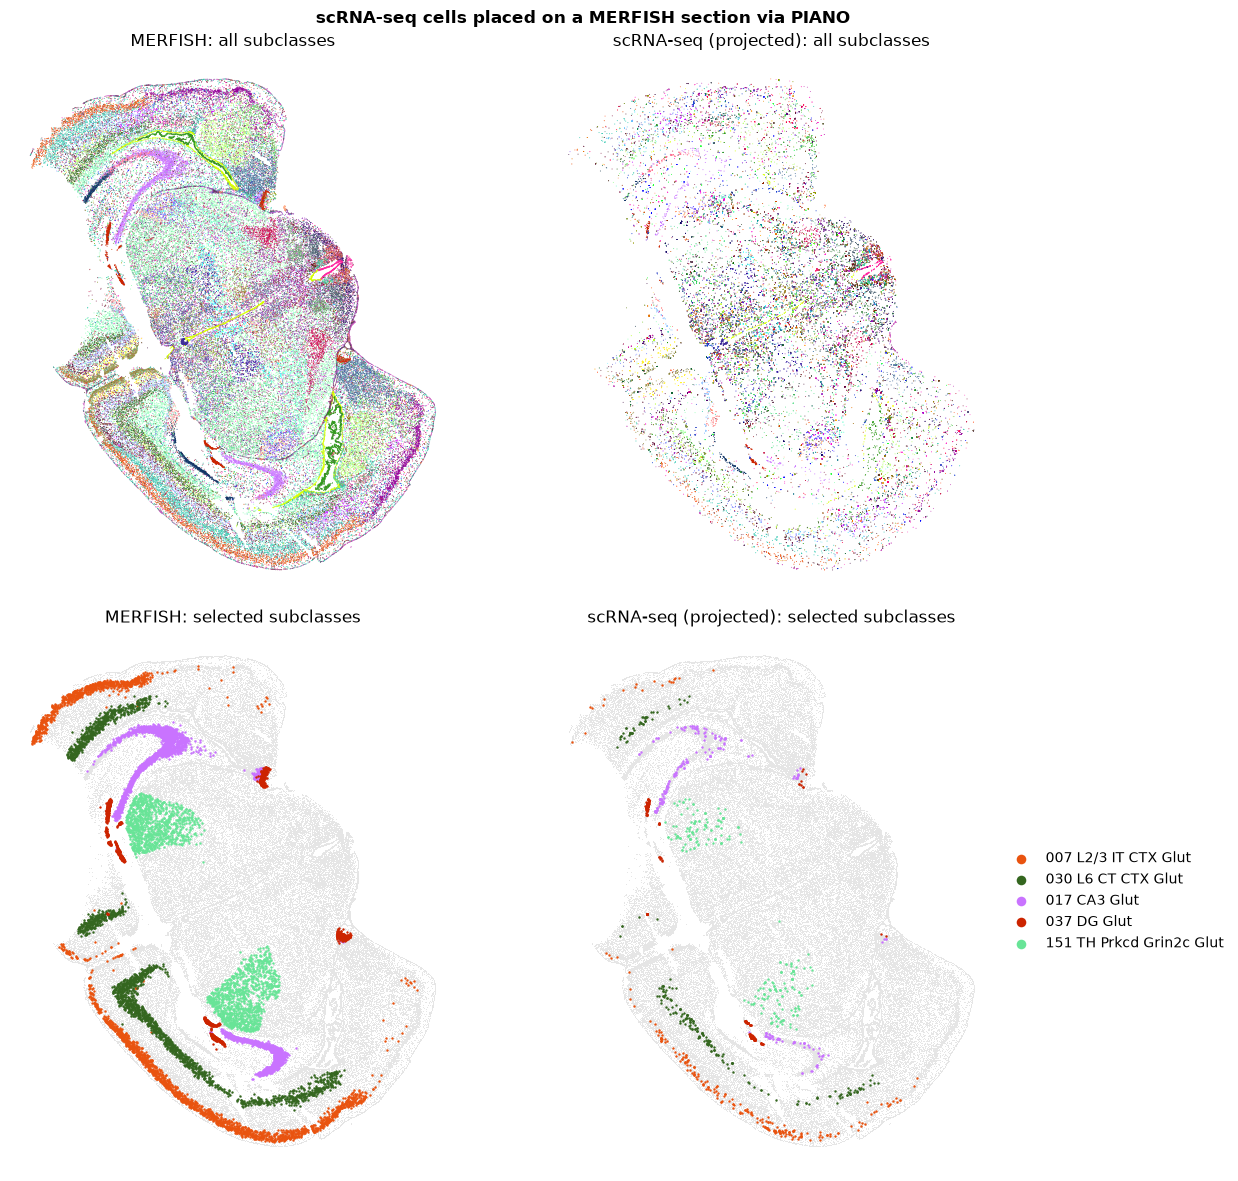

In [5]:
%matplotlib inline

palette = dict(merfish.obs.drop_duplicates("Subclass").set_index("Subclass")["color_hex_subclass"])  # Allen subclass colors
highlight = ["007 L2/3 IT CTX Glut", "030 L6 CT CTX Glut", "017 CA3 Glut", "037 DG Glut", "151 TH Prkcd Grin2c Glut"]  # cortex layers, hippocampus, thalamus

maps = [
    ("MERFISH", merfish_xy, merfish.obs["Subclass"].astype(str).to_numpy()),
    ("scRNA-seq (projected)", scrna.obsm["spatial_projected"], scrna.obs["Subclass"].astype(str).to_numpy()),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for j, (name, xy, subclass) in enumerate(maps):
    ax = axes[0, j]
    ax.scatter(xy[:, 0], xy[:, 1], c=[palette.get(s, "#cccccc") for s in subclass], s=0.5, rasterized=True, linewidths=0)
    ax.set_title(f"{name}: all subclasses")

    ax = axes[1, j]
    ax.scatter(merfish_xy[:, 0], merfish_xy[:, 1], c="#e5e5e5", s=0.5, rasterized=True, linewidths=0)
    for s in highlight:
        m = subclass == s
        ax.scatter(xy[m, 0], xy[m, 1], c=palette[s], s=3, rasterized=True, linewidths=0, label=s)
    ax.set_title(f"{name}: selected subclasses")

for ax in axes.ravel():
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
axes[1, 1].legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=4, frameon=False)

fig.suptitle("scRNA-seq cells placed on a MERFISH section via PIANO", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "sc_in_space.png", dpi=200, bbox_inches="tight")
plt.show()